# Base Models for Peatland CH4 Prediction

**Main question:** Does adding microbial data improve the prediction of CH4 at *unseen* peatland sites?


## 1. Setup

In [3]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, ElasticNet
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

RES_DIR = Path("results")
RES_DIR.mkdir(exist_ok=True)
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

SEED = 42
N_FOLDS = 10
INNER_FOLDS = 5

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "legend.frameon": False})

def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))

## 2. Data preparation

Same rules as in the pipeline:

* remove the 2 stations without CH4
* remove the 5 low-depth stations
* target = log10(CH4 + 100)
* genus reads become CLR values (pseudocount 0.5)
* missing values are filled with the median **inside** each training round

In [4]:
df_raw = pd.read_csv("MIEF-PEAT_CH4_dataset_v0.csv")

ENV = ["pH", "von_post_grade", "organic_matter_frac", "soil_moisture_vwc",
       "P_mg_kg", "K_mg_kg", "Ca_mg_kg", "Mg_mg_kg", "nitrate_mg_kg", "ammonium_mg_kg",
       "total_N_pct", "total_C_pct", "CN_ratio", "water_table_cm",
       "soil_temp_10cm_C", "soil_temp_20cm_C"]
SHARE = ["methanogen_share_pct", "methanotroph_share_pct"]
GENUS = [c for c in df_raw.columns if c.startswith("genus_")]

counts = df_raw[GENUS].astype(float)
log_counts = np.log(counts + 0.5)
clr = log_counts.sub(log_counts.mean(axis=1), axis=0)
CLR = ["clr_" + c[len("genus_"):] for c in GENUS]
clr.columns = CLR

df = pd.concat([df_raw, clr], axis=1)
df = df[df.CH4_ugC_m2_h.notna() & ~df.low_depth_flag].reset_index(drop=True)
df["y"] = np.log10(df.CH4_ugC_m2_h + 100)

y = df.y.to_numpy()
groups = df.site.to_numpy()

print(f"Stations: {len(df)}, sites: {df.site.nunique()}")
print(f"Environmental: {len(ENV)}, shares: {len(SHARE)}, genera (CLR): {len(CLR)}")
print(f"Missing values in environmental columns: {int(df[ENV].isna().sum().sum())}")

Stations: 189, sites: 75
Environmental: 16, shares: 2, genera (CLR): 210
Missing values in environmental columns: 55


In [5]:
FEATURES = {
    "Model 2 (env)": ENV,
    "Model 3 (env + shares)": ENV + SHARE,
    "Model 4 (env + genera)": ENV + CLR,
}
FSETS = list(FEATURES)

## 3. Cross-validation by site

In [6]:
folds = list(GroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(len(df)), groups=groups))

test_sites = [len(np.unique(groups[te])) for _, te in folds]
test_stations = [len(te) for _, te in folds]
print(f"{len(folds)} rounds, test sites per round: {min(test_sites)}-{max(test_sites)}, test stations per round: {min(test_stations)}-{max(test_stations)}")

10 rounds, test sites per round: 7-8, test stations per round: 14-25


## 4. Reference and Model 1

First, the two simple models from Step 4 of the pipeline. Every real model must beat them.

In [7]:
def score_fixed(make_model, cols):
    pred = np.full(len(y), np.nan)
    fold_rmse = []
    for tr, te in folds:
        m = make_model()
        m.fit(df.loc[tr, cols], y[tr])
        pred[te] = m.predict(df.loc[te, cols])
        fold_rmse.append(rmse(y[te], pred[te]))
    return {"pred": pred, "R2": r2_score(y, pred), "RMSE": rmse(y, pred), "fold_rmse": np.array(fold_rmse)}

simple = {
    "Reference (mean)": score_fixed(lambda: DummyRegressor(strategy="mean"), ["soil_moisture_vwc"]),
    "Model 1 (soil moisture)": score_fixed(
        lambda: Pipeline([("imp", SimpleImputer(strategy="median")), ("lr", LinearRegression())]), ["soil_moisture_vwc"]),
}

pd.DataFrame({k: {"R2": v["R2"], "RMSE": v["RMSE"], "RMSE spread (SD)": v["fold_rmse"].std(ddof=1)} for k, v in simple.items()}).T.round(3)

,R2,RMSE,RMSE spread (SD)
Reference (mean),-0.037,0.680,0.178
Model 1 (soil moisture),0.143,0.618,0.152


## 5. The six base models

| # | Model | Idea in simple words | Why it is useful here |
|---|---|---|---|
| 1 | Ridge regression | A straight-line model that keeps the weights small | Good when predictors are correlated |
| 2 | Elastic Net | A straight-line model that can set weights to zero | Picks useful predictors, good for many genera |
| 3 | SVR (RBF kernel) | Fits a smooth curve with a margin of error | Works with small data and curved patterns |
| 4 | KNN | Looks at the most similar stations | Very simple, no assumptions |
| 5 | Gradient Boosting | Many small trees, each fixes the errors of the last | Strong on tables, different from random forest |
| 6 | Neural network (MLP) | Small network with one or two layers | Can learn curved patterns |

All models use the same pipeline: median imputer, then scaling, then the model. Scaling is needed because the predictors have very different units.

In [8]:
def make_pipe(estimator):
    return Pipeline([("imp", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler()),
                     ("model", estimator)])

SPACES = {
    "Ridge": {
        "est": lambda: Ridge(),
        "params": {"alpha": ("log", [0.01, 0.1, 1, 10, 100, 1000])},
    },
    "Elastic Net": {
        "est": lambda: ElasticNet(max_iter=50000),
        "params": {"alpha": ("log", [0.001, 0.01, 0.1, 1]),
                   "l1_ratio": ("cat", [0.1, 0.5, 0.9])},
    },
    "SVR": {
        "est": lambda: SVR(kernel="rbf"),
        "params": {"C": ("log", [0.1, 1, 10, 100]),
                   "gamma": ("log", [0.0001, 0.001, 0.01, 0.1]),
                   "epsilon": ("log", [0.01, 0.03, 0.1, 0.3])},
    },
    "KNN": {
        "est": lambda: KNeighborsRegressor(),
        "params": {"n_neighbors": ("int", [3, 5, 10, 20, 30]),
                   "weights": ("cat", ["uniform", "distance"]),
                   "p": ("cat", [1, 2])},
    },
    "Gradient Boosting": {
        "est": lambda: GradientBoostingRegressor(subsample=0.8, random_state=SEED),
        "params": {"learning_rate": ("log", [0.03, 0.1, 0.3]),
                   "n_estimators": ("int", [50, 150, 300]),
                   "max_depth": ("int", [1, 2, 3])},
    },
    "MLP": {
        "est": lambda: MLPRegressor(solver="lbfgs", max_iter=3000, random_state=SEED),
        "params": {"hidden_layer_sizes": ("cat", [(8,), (32,), (16, 8)]),
                   "alpha": ("log", [0.001, 0.01, 0.1, 1, 10])},
    },
}
MODELS = list(SPACES)

## 6. Tuning, step by step

No guessing. The settings are found by the data in two steps:

* **Step A (coarse):** try a wide grid of values.
* **Step B (fine):** take the best value from Step A and search more closely around it, between its two neighbours.

Every try is scored on unseen sites: an inner cross-validation with 5 parts, again grouped by site. The metric is RMSE.

If the best value of Step A is at the edge of the grid, the fine search goes one step further outside.

In [9]:
inner_cv = GroupKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=SEED)

def to_grid(params):
    return {f"model__{k}": v for k, v in params.items()}

def refine(params, best):
    fine = {}
    for name, (kind, values) in params.items():
        b = best[f"model__{name}"]
        if kind == "cat":
            fine[name] = ("cat", [b])
            continue
        vals = sorted(values)
        i = vals.index(b)
        if kind == "log":
            lo = vals[i - 1] if i > 0 else b / (vals[1] / vals[0])
            hi = vals[i + 1] if i < len(vals) - 1 else b * (vals[-1] / vals[-2])
            new = np.geomspace(lo, hi, 5)
        else:
            lo = vals[i - 1] if i > 0 else max(1, b - (vals[1] - vals[0]))
            hi = vals[i + 1] if i < len(vals) - 1 else b + (vals[-1] - vals[-2])
            new = np.unique(np.round(np.linspace(lo, hi, 5)).astype(int))
            new = new[new >= 1]
        fine[name] = (kind, [float(v) if kind == "log" else int(v) for v in new])
    return fine

def search(est_fn, params, X, y_, g):
    gs = GridSearchCV(make_pipe(est_fn()), to_grid({k: v[1] for k, v in params.items()}),
                      cv=inner_cv, scoring="neg_root_mean_squared_error", n_jobs=-1, refit=False)
    gs.fit(X, y_, groups=g)
    return gs

def short(p):
    return {k.replace("model__", ""): (round(v, 5) if isinstance(v, float) else v) for k, v in p.items()}

The tuning uses the stations of all sites, but only to find the settings. The final scores in Step 7 are made again with a clean nested design, so they are fair.

In [10]:
TUNED = {}
rows = []

for fset in FSETS:
    X = df[FEATURES[fset]]
    for name in MODELS:
        spec = SPACES[name]
        gs1 = search(spec["est"], spec["params"], X, y, groups)
        fine = refine(spec["params"], gs1.best_params_)
        gs2 = search(spec["est"], fine, X, y, groups)
        TUNED[(name, fset)] = {"coarse": gs1, "fine": gs2, "fine_space": fine}
        rows.append({"features": fset, "model": name,
                     "coarse best": short(gs1.best_params_), "coarse RMSE": -gs1.best_score_,
                     "fine best": short(gs2.best_params_), "fine RMSE": -gs2.best_score_})
    print("done:", fset)

tuning_log = pd.DataFrame(rows)
tuning_log[["coarse RMSE", "fine RMSE"]] = tuning_log[["coarse RMSE", "fine RMSE"]].round(4)
tuning_log

done: Model 2 (env)
done: Model 3 (env + shares)
done: Model 4 (env + genera)


,features,model,coarse best,coarse RMSE,fine best,fine RMSE
0,Model 2 (env),Ridge,{'alpha': 1000},0.6367,{'alpha': 316.22777},0.6298
1,Model 2 (env),Elastic Net,"{'alpha': 0.1, 'l1_ratio': 0.9}",0.5938,"{'alpha': 0.1, 'l1_ratio': 0.9}",0.5938
2,Model 2 (env),SVR,"{'C': 1, 'epsilon': 0.03, 'gamma': 0.1}",0.5790,"{'C': 1.0, 'epsilon': 0.05623, 'gamma': 0.1}",0.5787
3,Model 2 (env),KNN,"{'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}",0.5670,"{'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}",0.5670
4,Model 2 (env),Gradient Boosting,"{'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 50}",0.5708,"{'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 76}",0.5709
5,Model 2 (env),MLP,"{'alpha': 10, 'hidden_layer_sizes': (8,)}",0.6052,"{'alpha': 10.0, 'hidden_layer_sizes': (8,)}",0.6052
6,Model 3 (env + shares),Ridge,{'alpha': 100},0.5781,{'alpha': 100.0},0.5781
7,Model 3 (env + shares),Elastic Net,"{'alpha': 0.1, 'l1_ratio': 0.5}",0.5565,"{'alpha': 0.1, 'l1_ratio': 0.5}",0.5565
8,Model 3 (env + shares),SVR,"{'C': 1, 'epsilon': 0.3, 'gamma': 0.01}",0.5653,"{'C': 1.0, 'epsilon': 0.17321, 'gamma': 0.03162}",0.5478
9,Model 3 (env + shares),KNN,"{'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}",0.5383,"{'n_neighbors': 4, 'p': 1, 'weights': 'uniform'}",0.5372


### What the tuning curves show

For Model 3 features, RMSE (inner cross-validation) against the main setting of each model. Grey = coarse search, blue = fine search. Lower is better. For each value we show the best result over the other settings.

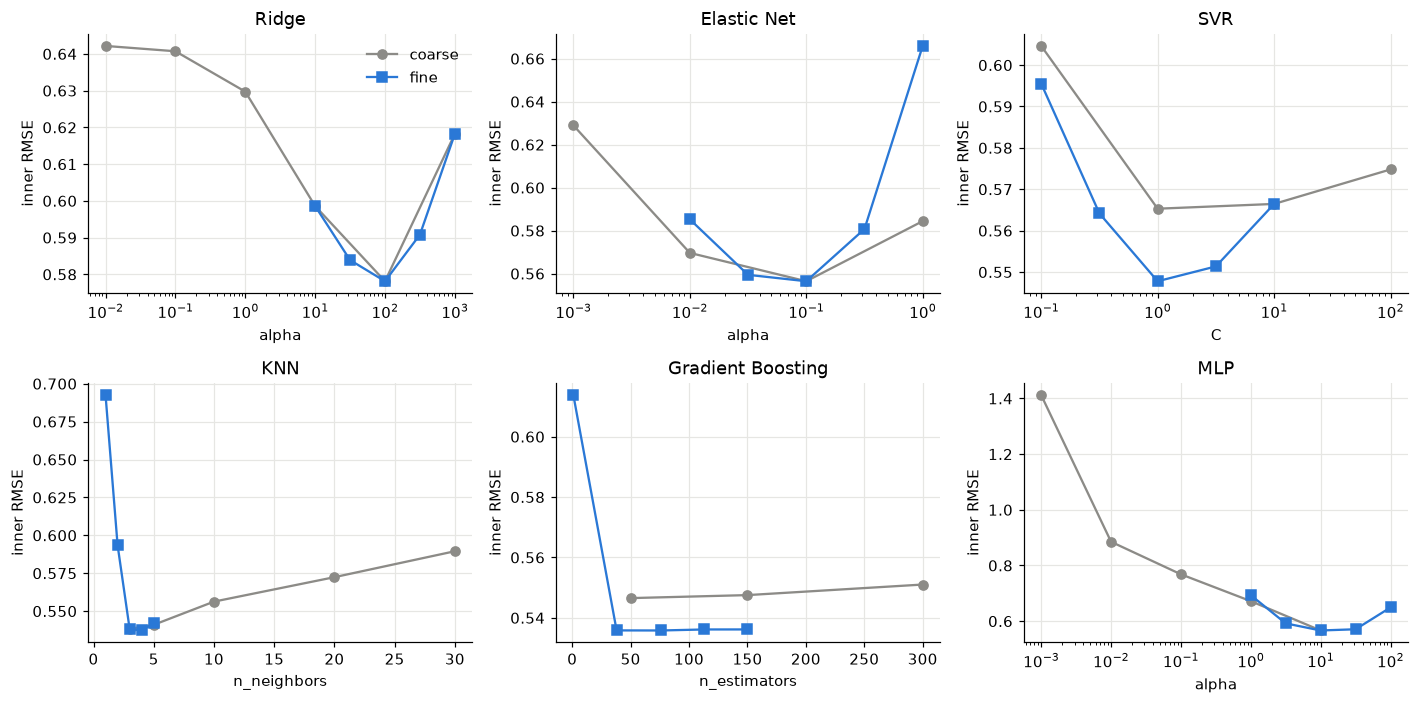

In [9]:
MAIN = {"Ridge": "alpha", "Elastic Net": "alpha", "SVR": "C", "KNN": "n_neighbors",
        "Gradient Boosting": "n_estimators", "MLP": "alpha"}

def curve(gs, param):
    r = pd.DataFrame(gs.cv_results_)
    col = f"param_model__{param}"
    r["rmse"] = -r["mean_test_score"]
    return r.groupby(col)["rmse"].min().reset_index().rename(columns={col: param}).sort_values(param)

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, name in zip(axes.ravel(), MODELS):
    t = TUNED[(name, "Model 3 (env + shares)")]
    p = MAIN[name]
    c1, c2 = curve(t["coarse"], p), curve(t["fine"], p)
    ax.plot(c1[p].astype(float), c1.rmse, "o-", color="#8c8b87", label="coarse")
    ax.plot(c2[p].astype(float), c2.rmse, "s-", color="#2a78d6", label="fine")
    if SPACES[name]["params"][p][0] == "log":
        ax.set_xscale("log")
    ax.set_title(name)
    ax.set_xlabel(p)
    ax.set_ylabel("inner RMSE")
axes[0, 0].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "base_tuning_curves.png")
plt.show()

## 7. Final scores on unseen sites (nested cross-validation)

For each of the 10 outer rounds:

1. Take the 9 training parts.
2. Run the fine grid search **only on them** (inner cross-validation by site).
3. Train with the best settings and predict the unseen test part.

The test sites are never used for tuning, imputing or scaling.

In [13]:
def nested_eval(name, fset):
    spec = SPACES[name]
    grid = to_grid({k: v[1] for k, v in TUNED[(name, fset)]["fine_space"].items()})
    X = df[FEATURES[fset]]
    pred = np.full(len(y), np.nan)
    fold_rmse, chosen = [], []
    for tr, te in folds:
        gs = GridSearchCV(make_pipe(spec["est"]()), grid, cv=inner_cv,
                          scoring="neg_root_mean_squared_error", n_jobs=-1, refit=True)
        gs.fit(X.iloc[tr], y[tr], groups=groups[tr])
        pred[te] = gs.predict(X.iloc[te])
        fold_rmse.append(rmse(y[te], pred[te]))
        chosen.append(short(gs.best_params_))
    return {"pred": pred, "R2": r2_score(y, pred), "RMSE": rmse(y, pred),
            "fold_rmse": np.array(fold_rmse), "chosen": chosen}

RESULTS = {}
for fset in FSETS:
    for name in MODELS:
        RESULTS[(name, fset)] = nested_eval(name, fset)
    print("done:", fset)

done: Model 2 (env)
done: Model 3 (env + shares)
done: Model 4 (env + genera)


In [11]:
rows = []
for name, r in simple.items():
    rows.append({"model": name, "features": "-", "R2": r["R2"], "RMSE": r["RMSE"],
                 "RMSE spread (SD)": r["fold_rmse"].std(ddof=1)})
for (name, fset), r in RESULTS.items():
    rows.append({"model": name, "features": fset, "R2": r["R2"], "RMSE": r["RMSE"],
                 "RMSE spread (SD)": r["fold_rmse"].std(ddof=1)})

scores = pd.DataFrame(rows)
scores.round(3)

,model,features,R2,RMSE,RMSE spread (SD)
0,Reference (mean),-,-0.037,0.680,0.178
1,Model 1 (soil moisture),-,0.143,0.618,0.152
2,Ridge,Model 2 (env),0.018,0.662,0.212
3,Elastic Net,Model 2 (env),-0.137,0.713,0.282
4,SVR,Model 2 (env),0.279,0.567,0.117
5,KNN,Model 2 (env),0.312,0.554,0.088
6,Gradient Boosting,Model 2 (env),0.282,0.566,0.118
7,MLP,Model 2 (env),0.238,0.583,0.126
8,Ridge,Model 3 (env + shares),0.206,0.595,0.169
9,Elastic Net,Model 3 (env + shares),0.277,0.568,0.142


In [12]:
view = scores[scores.features != "-"].pivot(index="model", columns="features", values=["R2", "RMSE"]).loc[MODELS]
view = view.reindex(columns=pd.MultiIndex.from_product([["R2", "RMSE"], FSETS]))
view.round(3)

R2                                                        RMSE                                              
                  Model 2 (env) Model 3 (env + shares) Model 4 (env + genera) Model 2 (env) Model 3 (env + shares) Model 4 (env + genera)
model                                                                                                                                    
Ridge                     0.018                  0.206                  0.516         0.662                  0.595                  0.465
Elastic Net              -0.137                  0.277                  0.548         0.713                  0.568                  0.449
SVR                       0.279                  0.264                  0.505         0.567                  0.573                  0.470
KNN                       0.312                  0.301                  0.349         0.554                  0.558                  0.539
Gradient Boosting         0.282                  0.332                  0.492         0.566                  0.546                  0.476
MLP                       0.238                  0.289                  0.469         0.583                  0.564                  0.487

### Comparison figure

Bars show RMSE on unseen sites (lower is better). Black lines show the spread across rounds. The dashed line is the reference model, the dotted line is Model 1.

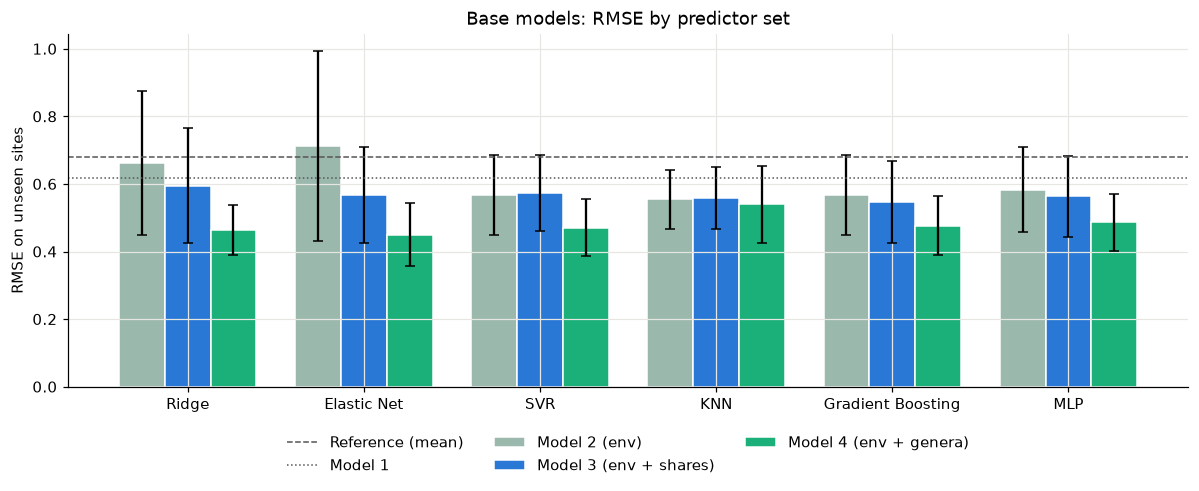

In [15]:
colors = {"Model 2 (env)": "#9bb8ad", "Model 3 (env + shares)": "#2a78d6", "Model 4 (env + genera)": "#1baf7a"}
x = np.arange(len(MODELS))
w = 0.26

fig, ax = plt.subplots(figsize=(11, 4.6))
for j, fset in enumerate(FSETS):
    m = [RESULTS[(n, fset)]["RMSE"] for n in MODELS]
    s = [RESULTS[(n, fset)]["fold_rmse"].std(ddof=1) for n in MODELS]
    ax.bar(x + (j - 1) * w, m, w, yerr=s, capsize=3, color=colors[fset], label=fset, edgecolor="white")

ax.axhline(simple["Reference (mean)"]["RMSE"], color="#555", ls="--", lw=1, label="Reference (mean)")
ax.axhline(simple["Model 1 (soil moisture)"]["RMSE"], color="#555", ls=":", lw=1, label="Model 1")
ax.set_xticks(x)
ax.set_xticklabels(MODELS)
ax.set_ylabel("RMSE on unseen sites")
ax.set_title("Base models: RMSE by predictor set")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
fig.savefig(FIG_DIR / "base_models_rmse.png")
plt.show()

## 8. Q3: do microbes help?

For each model we compare the same rounds, round by round. If the mean gain is **smaller than its spread**, the difference is not convincing.

Difference = RMSE of the smaller set minus RMSE of the bigger set. A positive number means microbes help.

In [14]:
rows = []
for name in MODELS:
    for base, other in [("Model 2 (env)", "Model 3 (env + shares)"), ("Model 2 (env)", "Model 4 (env + genera)")]:
        d = RESULTS[(name, base)]["fold_rmse"] - RESULTS[(name, other)]["fold_rmse"]
        rows.append({"model": name, "comparison": f"{base[:7]} vs {other[:7]}",
                     "mean gain": d.mean(), "spread (SD)": d.std(ddof=1),
                     "rounds won": f"{(d > 0).sum()}/{len(d)}",
                     "convincing": bool(d.mean() > d.std(ddof=1))})

q3 = pd.DataFrame(rows)
q3[["mean gain", "spread (SD)"]] = q3[["mean gain", "spread (SD)"]].round(3)
q3

,model,comparison,mean gain,spread (SD),rounds won,convincing
0,Ridge,Model 2 vs Model 3,0.055,0.079,7/10,False
1,Ridge,Model 2 vs Model 4,0.171,0.164,9/10,True
2,Elastic Net,Model 2 vs Model 3,0.104,0.169,8/10,False
3,Elastic Net,Model 2 vs Model 4,0.215,0.223,9/10,False
4,SVR,Model 2 vs Model 3,-0.009,0.053,5/10,False
5,SVR,Model 2 vs Model 4,0.093,0.098,8/10,False
6,KNN,Model 2 vs Model 3,-0.004,0.045,6/10,False
7,KNN,Model 2 vs Model 4,0.013,0.106,7/10,False
8,Gradient Boosting,Model 2 vs Model 3,0.017,0.048,5/10,False
9,Gradient Boosting,Model 2 vs Model 4,0.078,0.097,8/10,False


## 9. Measured vs predicted

The best base model with Model 3 features, one dot per station.

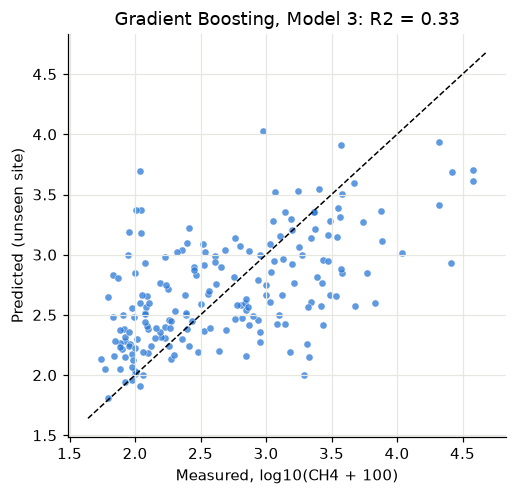

In [15]:
best = min(MODELS, key=lambda n: RESULTS[(n, "Model 3 (env + shares)")]["RMSE"])
r = RESULTS[(best, "Model 3 (env + shares)")]

fig, ax = plt.subplots(figsize=(4.8, 4.6))
ax.scatter(y, r["pred"], s=22, color="#2a78d6", alpha=0.75, edgecolor="white", linewidth=0.4)
lim = [min(y.min(), np.nanmin(r["pred"])) - 0.1, max(y.max(), np.nanmax(r["pred"])) + 0.1]
ax.plot(lim, lim, "k--", lw=1)
ax.set_xlabel("Measured, log10(CH4 + 100)")
ax.set_ylabel("Predicted (unseen site)")
ax.set_title(f"{best}, Model 3: R2 = {r['R2']:.2f}")
fig.tight_layout()
fig.savefig(FIG_DIR / "base_best_measured_vs_predicted.png")
plt.show()

## 10. Comparison with Yasin's models

Her notebook `Prediction_Peatland_CH4.ipynb` has the reference model, Model 1 and Model 1b. I run the same models on my side with the same rounds, so I can check that the numbers match. Her random forests are not ready yet, so they are left as empty rows.

In [16]:
def water_table_model():
    return score_fixed(lambda: Pipeline([("imp", SimpleImputer(strategy="median")), ("lr", LinearRegression())]), ["water_table_cm"])

simple["Model 1b (water table)"] = water_table_model()

team = pd.DataFrame({
    "R2": {"Reference (mean)": -0.037, "Model 1 (soil moisture)": 0.143, "Model 1b (water table)": 0.232},
    "RMSE": {"Reference (mean)": 0.680, "Model 1 (soil moisture)": 0.618, "Model 1b (water table)": 0.585},
})

check = pd.DataFrame({k: {"R2 (mine)": v["R2"], "R2 (teammate)": team.loc[k, "R2"],
                          "RMSE (mine)": v["RMSE"], "RMSE (teammate)": team.loc[k, "RMSE"]} for k, v in simple.items()}).T
check.round(3)

,R2 (mine),R2 (teammate),RMSE (mine),RMSE (teammate)
Reference (mean),-0.037,-0.037,0.680,0.680
Model 1 (soil moisture),0.143,0.143,0.618,0.618
Model 1b (water table),0.232,0.232,0.585,0.585


In [17]:
def cell(r):
    return f"{r['RMSE']:.3f} ({r['R2']:.2f})"

table = pd.DataFrame(index=["Reference (mean)", "Model 1 (soil moisture)", "Model 1b (water table)"] + MODELS + ["Random forest (teammate)"],
                     columns=["Simple"] + FSETS, dtype=object).fillna("")

for k in ["Reference (mean)", "Model 1 (soil moisture)", "Model 1b (water table)"]:
    table.loc[k, "Simple"] = cell(simple[k])
for name in MODELS:
    for fset in FSETS:
        table.loc[name, fset] = cell(RESULTS[(name, fset)])

table.loc["Random forest (teammate)"] = ["", "to add", "to add", "to add"]
table

,Simple,Model 2 (env),Model 3 (env + shares),Model 4 (env + genera)
Reference (mean),0.680 (-0.04),,,
Model 1 (soil moisture),0.618 (0.14),,,
Model 1b (water table),0.585 (0.23),,,
Ridge,,0.662 (0.02),0.595 (0.21),0.465 (0.52)
Elastic Net,,0.713 (-0.14),0.568 (0.28),0.449 (0.55)
SVR,,0.567 (0.28),0.573 (0.26),0.470 (0.51)
KNN,,0.554 (0.31),0.558 (0.30),0.539 (0.35)
Gradient Boosting,,0.566 (0.28),0.546 (0.33),0.476 (0.49)
MLP,,0.583 (0.24),0.564 (0.29),0.487 (0.47)
Random forest (teammate),,to add,to add,to add


In [18]:
ranking = scores[scores.features != "-"].sort_values("RMSE").head(5)[["model", "features", "R2", "RMSE", "RMSE spread (SD)"]].round(3)
ranking.reset_index(drop=True)

,model,features,R2,RMSE,RMSE spread (SD)
0,Elastic Net,Model 4 (env + genera),0.548,0.449,0.094
1,Ridge,Model 4 (env + genera),0.516,0.465,0.074
2,SVR,Model 4 (env + genera),0.505,0.470,0.084
3,Gradient Boosting,Model 4 (env + genera),0.492,0.476,0.088
4,MLP,Model 4 (env + genera),0.469,0.487,0.084


## 11. Settings chosen in the outer rounds

In [19]:
rows = []
for (name, fset), r in RESULTS.items():
    for i, c in enumerate(r["chosen"], 1):
        rows.append({"model": name, "features": fset, "round": i, **{k: str(v) for k, v in c.items()}})
chosen = pd.DataFrame(rows)

chosen[chosen.features == "Model 3 (env + shares)"].drop(columns="features").set_index(["model", "round"]).dropna(axis=1, how="all").fillna("")

alpha l1_ratio        C  epsilon    gamma n_neighbors  p  weights learning_rate max_depth n_estimators hidden_layer_sizes
model             round                                                                                                                              
Ridge             1      31.62278                                                                                                                    
                  2         100.0                                                                                                                    
                  3         100.0                                                                                                                    
                  4      31.62278                                                                                                                    
                  5      31.62278                                                                                                                    
                  6      31.62278                                                                                                                    
                  7         100.0                                                                                                                    
                  8         100.0                                                                                                                    
                  9         100.0                                                                                                                    
                  10        100.0                                                                                                                    
Elastic Net       1       0.03162      0.5                                                                                                           
                  2       0.03162      0.5                                                                                                           
                  3       0.03162      0.5                                                                                                           
                  4           0.1      0.5                                                                                                           
                  5           0.1      0.5                                                                                                           
                  6           0.1      0.5                                                                                                           
                  7           0.1      0.5                                                                                                           
                  8       0.03162      0.5                                                                                                           
                  9           0.1      0.5                                                                                                           
                  10          0.1      0.5                                                                                                           
SVR               1                         3.16228      0.1  0.00316                                                                                
                  2                            10.0      0.3     0.01                                                                                
                  3                             1.0  0.17321  0.03162                                                                                
                  4                             1.0  0.17321     0.01                                                                                
                  5                         3.16228      0.3  0.00316                                                           

If the settings change a lot from round to round, the model is not stable.

In [20]:
stable = []
for (name, fset), r in RESULTS.items():
    n_unique = pd.Series([str(c) for c in r["chosen"]]).nunique()
    stable.append({"model": name, "features": fset, "different settings in 10 rounds": n_unique})

pd.DataFrame(stable).pivot(index="model", columns="features", values="different settings in 10 rounds").loc[MODELS][FSETS]

features,Model 2 (env),Model 3 (env + shares),Model 4 (env + genera)
model,,,
Ridge,2,2,2
Elastic Net,2,2,2
SVR,9,8,5
KNN,4,4,4
Gradient Boosting,10,8,7
MLP,2,2,2


## 12. Save results

In [21]:
scores.round(4).to_csv(RES_DIR / "base_models_scores.csv", index=False)
q3.to_csv(RES_DIR / "base_models_q3.csv", index=False)
table.to_csv(RES_DIR / "base_models_summary_table.csv")
tuning_log.to_csv(RES_DIR / "base_models_tuning_log.csv", index=False)

pred_table = df[["station_id", "site", "y"]].copy()
for (name, fset), r in RESULTS.items():
    pred_table[f"{name} | {fset}"] = r["pred"]
pred_table.to_csv(RES_DIR / "base_models_predictions.csv", index=False)

print("saved to", RES_DIR.resolve())

saved to /Users/sofiiapopeniuk/Documents/IDS/results


## 13. Summary

In [22]:
best_by_set = {fset: min(MODELS, key=lambda n: RESULTS[(n, fset)]["RMSE"]) for fset in FSETS}
n_convincing = int(q3.convincing.sum())

print(f"Stations: {len(df)}, sites: {df.site.nunique()}")
print(f"Reference RMSE: {simple['Reference (mean)']['RMSE']:.3f}, Model 1 RMSE: {simple['Model 1 (soil moisture)']['RMSE']:.3f}, R2: {simple['Model 1 (soil moisture)']['R2']:.3f}")
print()
for fset in FSETS:
    n = best_by_set[fset]
    r = RESULTS[(n, fset)]
    print(f"Best base model for {fset}: {n}, R2 = {r['R2']:.3f}, RMSE = {r['RMSE']:.3f}")
print()
print(f"Convincing gains from microbes: {n_convincing} of {len(q3)} comparisons")
print(f"Models with Model 2 predictors that beat the reference: {sum(RESULTS[(n, 'Model 2 (env)')]['RMSE'] < simple['Reference (mean)']['RMSE'] for n in MODELS)} of {len(MODELS)}")

Stations: 189, sites: 75
Reference RMSE: 0.680, Model 1 RMSE: 0.618, R2: 0.143

Best base model for Model 2 (env): KNN, R2 = 0.312, RMSE = 0.554
Best base model for Model 3 (env + shares): Gradient Boosting, R2 = 0.332, RMSE = 0.546
Best base model for Model 4 (env + genera): Elastic Net, R2 = 0.548, RMSE = 0.449

Convincing gains from microbes: 1 of 12 comparisons
Models with Model 2 predictors that beat the reference: 5 of 6


## 14. Three more base models

Three more models with different ideas. I use the same pipeline, the same tuning steps and the same unseen-site rounds as before.

| # | Model | Idea in simple words | Why it is useful here |
|---|---|---|---|
| 7 | PLS regression | Builds a few new "mixed" predictors from many correlated ones | Made for many correlated predictors, like genera |
| 8 | Kernel Ridge (RBF) | Ridge regression that can fit curves | Like SVR, but simpler loss |
| 9 | Gaussian Process | Predicts from similar stations, smooth curve | Good on small data |

In [11]:
from sklearn.cross_decomposition import PLSRegression
from sklearn.kernel_ridge import KernelRidge
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF

class PLS1(PLSRegression):
    def predict(self, X, copy=True):
        return np.ravel(super().predict(X, copy=copy))

EXTRA_SPACES = {
    "PLS": {
        "est": lambda: PLS1(scale=False),
        "params": {"n_components": ("int", [1, 2, 4, 8, 12])},
    },
    "Kernel Ridge": {
        "est": lambda: KernelRidge(kernel="rbf"),
        "params": {"alpha": ("log", [0.01, 0.1, 1, 10]),
                   "gamma": ("log", [0.0001, 0.001, 0.01, 0.1])},
    },
    "Gaussian Process": {
        "est": lambda: GaussianProcessRegressor(kernel=RBF(1.0), optimizer=None, normalize_y=True),
        "params": {"alpha": ("log", [0.03, 0.1, 0.3, 1]),
                   "kernel__length_scale": ("log", [1, 3, 10, 30, 100])},
    },
}
SPACES.update(EXTRA_SPACES)
EXTRA = list(EXTRA_SPACES)
ALL_MODELS = MODELS + EXTRA

### Tuning (coarse, then fine) for the new models

In [12]:
rows = []

for fset in FSETS:
    X = df[FEATURES[fset]]
    for name in EXTRA:
        spec = SPACES[name]
        gs1 = search(spec["est"], spec["params"], X, y, groups)
        fine = refine(spec["params"], gs1.best_params_)
        gs2 = search(spec["est"], fine, X, y, groups)
        TUNED[(name, fset)] = {"coarse": gs1, "fine": gs2, "fine_space": fine}
        rows.append({"features": fset, "model": name,
                     "coarse best": short(gs1.best_params_), "coarse RMSE": -gs1.best_score_,
                     "fine best": short(gs2.best_params_), "fine RMSE": -gs2.best_score_})
    print("done:", fset)

tuning_log_extra = pd.DataFrame(rows)
tuning_log_extra[["coarse RMSE", "fine RMSE"]] = tuning_log_extra[["coarse RMSE", "fine RMSE"]].round(4)
tuning_log_extra

done: Model 2 (env)
done: Model 3 (env + shares)
done: Model 4 (env + genera)


,features,model,coarse best,coarse RMSE,fine best,fine RMSE
0,Model 2 (env),PLS,{'n_components': 2},0.6479,{'n_components': 2},0.6479
1,Model 2 (env),Kernel Ridge,"{'alpha': 0.01, 'gamma': 0.001}",0.6357,"{'alpha': 0.001, 'gamma': 0.00032}",0.6195
2,Model 2 (env),Gaussian Process,"{'alpha': 0.3, 'kernel__length_scale': 3}",0.5766,"{'alpha': 0.31623, 'kernel__length_scale': 3.16228}",0.5754
3,Model 3 (env + shares),PLS,{'n_components': 2},0.5619,{'n_components': 2},0.5619
4,Model 3 (env + shares),Kernel Ridge,"{'alpha': 0.01, 'gamma': 0.0001}",0.5806,"{'alpha': 0.00316, 'gamma': 3e-05}",0.5798
5,Model 3 (env + shares),Gaussian Process,"{'alpha': 0.3, 'kernel__length_scale': 3}",0.5607,"{'alpha': 0.56234, 'kernel__length_scale': 3.16228}",0.5591
6,Model 4 (env + genera),PLS,{'n_components': 4},0.4948,{'n_components': 4},0.4948
7,Model 4 (env + genera),Kernel Ridge,"{'alpha': 0.1, 'gamma': 0.0001}",0.4803,"{'alpha': 0.03162, 'gamma': 3e-05}",0.4775
8,Model 4 (env + genera),Gaussian Process,"{'alpha': 0.03, 'kernel__length_scale': 100}",0.4783,"{'alpha': 0.1, 'kernel__length_scale': 54.77226}",0.4772


### Final scores for the new models (nested cross-validation)

Same rules as in Section 7.

In [14]:
for fset in FSETS:
    for name in EXTRA:
        RESULTS[(name, fset)] = nested_eval(name, fset)
    print("done:", fset)

rows = []
for name in ALL_MODELS:
    for fset in FSETS:
        r = RESULTS[(name, fset)]
        rows.append({"model": name, "features": fset, "R2": r["R2"], "RMSE": r["RMSE"],
                     "RMSE spread (SD)": r["fold_rmse"].std(ddof=1)})
scores_all = pd.DataFrame(rows)

view_all = scores_all.pivot(index="model", columns="features", values=["R2", "RMSE"]).loc[ALL_MODELS]
view_all = view_all.reindex(columns=pd.MultiIndex.from_product([["R2", "RMSE"], FSETS]))
view_all.round(3)

done: Model 2 (env)
done: Model 3 (env + shares)
done: Model 4 (env + genera)


R2                                                        RMSE                                              
                  Model 2 (env) Model 3 (env + shares) Model 4 (env + genera) Model 2 (env) Model 3 (env + shares) Model 4 (env + genera)
model                                                                                                                                    
Ridge                     0.018                  0.206                  0.516         0.662                  0.595                  0.465
Elastic Net              -0.137                  0.277                  0.548         0.713                  0.568                  0.449
SVR                       0.279                  0.264                  0.505         0.567                  0.573                  0.470
KNN                       0.312                  0.301                  0.349         0.554                  0.558                  0.539
Gradient Boosting         0.282                  0.332                  0.492         0.566                  0.546                  0.476
MLP                       0.238                  0.289                  0.469         0.583                  0.564                  0.487
PLS                       0.075                  0.324                  0.436         0.643                  0.549                  0.502
Kernel Ridge              0.118                  0.228                  0.519         0.627                  0.587                  0.464
Gaussian Process          0.303                  0.300                  0.510         0.558                  0.559                  0.468

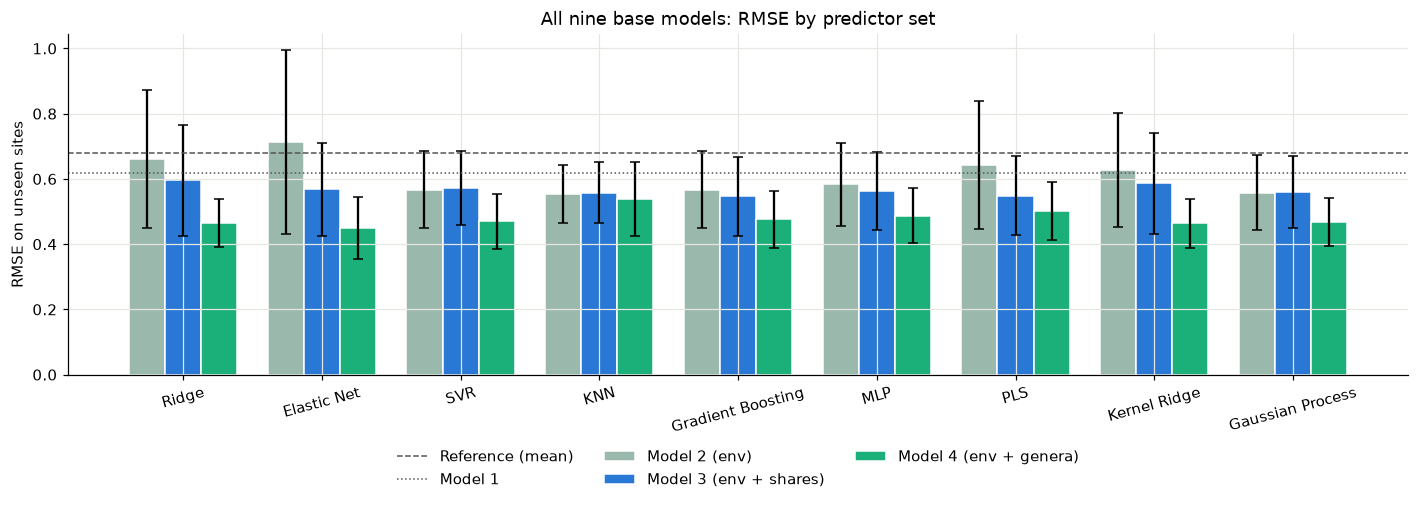

In [18]:
x = np.arange(len(ALL_MODELS))
w = 0.26

fig, ax = plt.subplots(figsize=(13, 4.8))
for j, fset in enumerate(FSETS):
    m = [RESULTS[(n, fset)]["RMSE"] for n in ALL_MODELS]
    s = [RESULTS[(n, fset)]["fold_rmse"].std(ddof=1) for n in ALL_MODELS]
    ax.bar(x + (j - 1) * w, m, w, yerr=s, capsize=3, color=colors[fset], label=fset, edgecolor="white")

ax.axhline(simple["Reference (mean)"]["RMSE"], color="#555", ls="--", lw=1, label="Reference (mean)")
ax.axhline(simple["Model 1 (soil moisture)"]["RMSE"], color="#555", ls=":", lw=1, label="Model 1")
ax.set_xticks(x)
ax.set_xticklabels(ALL_MODELS, rotation=15)
ax.set_ylabel("RMSE on unseen sites")
ax.set_title("All nine base models: RMSE by predictor set")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
fig.tight_layout()
fig.savefig(FIG_DIR / "base_models_rmse_all9.png")
plt.show()

In [19]:
rows = []
for name in ALL_MODELS:
    for base, other in [("Model 2 (env)", "Model 3 (env + shares)"), ("Model 2 (env)", "Model 4 (env + genera)")]:
        d = RESULTS[(name, base)]["fold_rmse"] - RESULTS[(name, other)]["fold_rmse"]
        rows.append({"model": name, "comparison": f"{base[:7]} vs {other[:7]}",
                     "mean gain": d.mean(), "spread (SD)": d.std(ddof=1),
                     "rounds won": f"{(d > 0).sum()}/{len(d)}",
                     "convincing": bool(d.mean() > d.std(ddof=1))})

q3_all = pd.DataFrame(rows)
q3_all[["mean gain", "spread (SD)"]] = q3_all[["mean gain", "spread (SD)"]].round(3)
q3_all[q3_all.model.isin(EXTRA)]

,model,comparison,mean gain,spread (SD),rounds won,convincing
12,PLS,Model 2 vs Model 3,0.073,0.107,8/10,False
13,PLS,Model 2 vs Model 4,0.121,0.164,7/10,False
14,Kernel Ridge,Model 2 vs Model 3,0.033,0.052,7/10,False
15,Kernel Ridge,Model 2 vs Model 4,0.144,0.130,9/10,True
16,Gaussian Process,Model 2 vs Model 3,-0.007,0.054,4/10,False
17,Gaussian Process,Model 2 vs Model 4,0.082,0.084,8/10,False


In [20]:
table_all = pd.DataFrame(index=["Reference (mean)", "Model 1 (soil moisture)", "Model 1b (water table)"] + ALL_MODELS + ["Random forest (teammate)"],
                         columns=["Simple"] + FSETS, dtype=object).fillna("")

for k in ["Reference (mean)", "Model 1 (soil moisture)", "Model 1b (water table)"]:
    table_all.loc[k, "Simple"] = cell(simple[k])
for name in ALL_MODELS:
    for fset in FSETS:
        table_all.loc[name, fset] = cell(RESULTS[(name, fset)])
table_all.loc["Random forest (teammate)"] = ["", "to add", "to add", "to add"]

table_all.to_csv(RES_DIR / "base_models_summary_table_all9.csv")
scores_all.round(4).to_csv(RES_DIR / "base_models_scores_all9.csv", index=False)
q3_all.to_csv(RES_DIR / "base_models_q3_all9.csv", index=False)
pd.concat([tuning_log, tuning_log_extra]).to_csv(RES_DIR / "base_models_tuning_log_all9.csv", index=False)

pred_all = df[["station_id", "site", "y"]].copy()
for (name, fset), r in RESULTS.items():
    pred_all[f"{name} | {fset}"] = r["pred"]
pred_all.to_csv(RES_DIR / "base_models_predictions_all9.csv", index=False)

table_all

,Simple,Model 2 (env),Model 3 (env + shares),Model 4 (env + genera)
Reference (mean),0.680 (-0.04),,,
Model 1 (soil moisture),0.618 (0.14),,,
Model 1b (water table),0.585 (0.23),,,
Ridge,,0.662 (0.02),0.595 (0.21),0.465 (0.52)
Elastic Net,,0.713 (-0.14),0.568 (0.28),0.449 (0.55)
SVR,,0.567 (0.28),0.573 (0.26),0.470 (0.51)
KNN,,0.554 (0.31),0.558 (0.30),0.539 (0.35)
Gradient Boosting,,0.566 (0.28),0.546 (0.33),0.476 (0.49)
MLP,,0.583 (0.24),0.564 (0.29),0.487 (0.47)
PLS,,0.643 (0.07),0.549 (0.32),0.502 (0.44)


### Notes and limits

* Only 75 sites, so the scores move a lot between rounds. Always read the score together with the spread.
* The microbial data show potential, not real activity.
* The tuning step uses all sites to find the settings. The final scores are nested, so they stay fair.
* Random forests are done by my teammate; her scores can be added to the same table and figure.